# 51 Peg - Advanced

This section is a hands-on tutorial on how to make a run taking advantage of `EMPEROR`'s options.
Similarly to the previous tutorial, we use the 51 Peg RV data available on [GitHub](https://github.com/ReddTea/astroemperor/tree/main/tests/datafiles/51Peg/RV).

First, we start our simulation:

In [1]:
from IPython.display import Image

import astroemperor as emp
import numpy as np
np.random.seed(1234)


sim = emp.Simulation()
sim.load_data('51Peg')  # folder read from /datafiles/

I couldnt grab the terminal size. Trying with pandas...
Terminal size with pandas successful!
                                                                                
                   ~~ Simulation Successfully Initialized ~~                    
                                                                                


                         
Reading data from 51peg.vels                          








## General Options
We take a deeper look into the Emperor options, starting with parallelisation, and sampler backend.


### Parallelisation
Parallelisation can be done with several different libraries. The available options are:

```multiprocess_method```: To change the parallelisation scheme.

```cores__```: Misnomer for how many threads (and not cores) to use.


| Code | Library         | Pool           |
|------|-----------------|----------------|
| 0    | None            | None           |
| 1    | multiprocessing | Pool           |
| 2    | multiprocess    | Pool           |
| 3    | multiprocessing | ThreadPool     |
| 4    | pathos          | ProcessingPool |
| 5    | schwimmbad      | SerialPool     |
| 6    | schwimmbad      | JoblibPool     |
| 7    | schwimmbad      | MultiPool      |


If you want a custom parallelisation scheme, you can add the script directly into the `astroemperor/support/pools` folder, as a file named `08.pool`, and then use it directly in EMPEROR with
```multiprocess_method = 8```.


### Sampler backend
`reddemcee` has two different backends. `PTBackend` is the default, working exclusively with RAM, and `HDFBackend`, stores the chain in an HDF5 file using `h5py`, saving it there step-by-step.

The first one is faster, but requires a higher RAM usage.

The second one is safer and less memory-hungry. To use the h5 backend, simply change the `backend_bool` attribute to `True`.

In [2]:
sim.multiprocess_method = 1  # multiprocessing Pool
sim.cores__ = 12  # threads for the run
sim.backend_bool = False  # True for h5py backend

## Engine configuration

We add ```set_engine``` with some custom options. We will use a different starting temperature ladder. A good initial ladder increases the efficiency of the adaptation, in the same way a good initial guess for the parameters increases the convergence time.

We will use a different adaptation algorithm, based on the specific heat of the system. We also change the adaptation rate, and decay timescale.

In [3]:
ntemps, nwalkers, nsweeps, nsteps = 11, 128, 3000, 1
sim.set_engine('reddemcee')


sim.engine_config['setup'] = [ntemps, nwalkers, nsweeps, nsteps]

sim.engine_config['betas'] = list(np.linspace(1, 0, ntemps))

sim.engine_config['tsw_history'] = True  # save temperature swaps per sweep
sim.engine_config['smd_history'] = True  # save swap mean distance per sweep

sim.engine_config['adapt_tau'] = 100
sim.engine_config['adapt_nu'] = 1.5
sim.engine_config['adapt_mode'] = 'SAR'  # uniform Swap Acceptance Rate

## Run Configuration

Here we can add keywords for the engine running. For `reddemcee`, we have:
`burnin`, `adaptation_batches`, `adaptation_nsweeps`, `thin`, `discard`, and `logger_level`. 

We will set up a 10\% burn-in phase.

In [4]:
sim.run_config['burnin'] = 0.1

### Model Comparison
In our example, instead of comparing BIC we will compare Evidences directly.
We can change the evidence estimation method between Curvature-aware Thermodynamic Integration (TI+), Geometric-Bridge Stepping Stones (SS+), and a Hybrid algorithm (for more details see the [reddemcee paper](https://arxiv.org/abs/2509.24870)).

In [5]:
sim.set_comparison_criteria('Evidence')
sim.set_tolerance(10)  # difference between models

sim.evidence_method = 'ss'  # ti, ss, hybrid

Comparison Criteria set to Evidence
Comparison Criteria Tolerance set to 10


## Model Setup

We feed the name of the instrument (optional), as well as the stellar mass for calculating the minimum-mass and semi-major axis, and stellar mass error (optional). We will use the Keplerian parameterisation $(P, K, \phi, e, \omega)$. 

We add some boundaries and initial positions to speed up the process:

In [6]:
sim.instrument_names_RV = ['LICK']
sim.starmass = 1.12  # in solar masses
sim.starmass_err = 0.04
sim.keplerian_parameterisation = 0


sim.add_condition(['Period 1',      'limits', [3, 5]])
sim.add_condition(['Amplitude 1',   'limits', [45, 60]])
sim.add_condition(['Eccentricity 1','limits', [0, 0.5]])
sim.add_condition(['Offset 1',      'limits', [-10., 10.]])

sim.add_condition(['Period 1',      'init_pos', [4.1, 4.3]])
sim.add_condition(['Amplitude 1',   'init_pos', [50, 60]])
sim.add_condition(['Eccentricity 1','init_pos', [0, 0.1]])

## Plotting Options
We add some plotting options to speed up this test a little. We will only plot the posteriors for the cold chain, and two intermediate chains. Also, we won't use the `arviz` optional plots.

In [7]:
sim.plot_posteriors['temps'] = [0]
sim.plot_trace['plot'] = False
sim.plot_gaussian_mixtures['plot'] = False

## Run and Results

Finally, we run our simulation (it will take some minutes):

In [8]:
sim.autorun(0, 1)

                              Offset block added, OffsetBlock


                              Jitter block added, JitterBlock



Condition applied: Parameter Offset 1 attribute limits set to [-10.0, 10.0]


                                ~~ Setup Info ~~                                


Current Engine is            reddemcee 1.0
Number of cores is           12
Save location is             datalogs/51Peg/run_2/k0
Dynamical Criteria is        None
Posterior fit method is      Gaussian Mixtures
Limits constrain method is   range
Model Selection method is    Evidence


                           ~~ Automatically Saving ~~                           


Logger       : ✔
Samples      : ✘
Posteriors   : ✔
Likelihoods  : ✔
Plots: Posteriors           : ✔
Plots: Keplerian Model      : ✔
Plots: Gaussian Mixture     : ✘
Plots: Parameter Histograms : ✔
Plots: Corner               : ✔


                               ~~ Pre-Run Info ~~                               


Parameter    Prior            

100%|██████████| 33000/33000 [00:51<00:00, 639.60it/s]


temp_script.py took 51.687 seconds

 FAILED 
 multiprocessing.set_start_method(fork, force=True)

Method set to  fork
Autocorrelation tolerance=50 fails. Setting to 0.
                         Calculating Gaussian Mixtures                          


100%|██████████| 2/2 [00:00<00:00,  3.14it/s]



                                 ~~ Best Fit ~~                                 


Parameter      Value(max)  Range(±σ)          Prior               Limits
-----------  ------------  -----------------  ------------------  -------------
Offset 1           -0.148  [-1.078, 1.073]    ~𝓤 (-10.0, 10.0)    [-10, 10]

-----------  ------------  -----------------  ------------------  -------------
Jitter 1           36.062  [-0.622, 0.701]    ~𝓝 (5, 5)           [0, 75.852]




                                 ~~ Run Info ~~                                 






Info                                 Value
-----------------------------------  ----------------------------------------------------------------------------------------
Star Name                      :     51Peg
The sample sizes are           :     [345600, 345600, 345600, 345600, 345600, 345600, 345600, 345600, 345600, 345600, 345600]
Temps, Walkers, Sweeps, Steps  :     [11, 128, 3000, 1]
Model used is                  :     ['Off

...



                             Plotting Beta Density                              


100%|██████████| 1/1 [00:00<00:00, 15.76it/s]




                           Plotting Temperature Rates                           


100%|██████████| 10/10 [00:00<00:00, 37.71it/s]





Time Table
Time RUN                   : 00:00:56
Time POSTPROCESS           : 00:00:05
Time CALCULATE GM          : 00:00:03
Time plot_posteriors       : 00:00:03
Time plot_histograms       : 00:00:07
Time plot_keplerian_model  : 00:00:00
Time plot_betas            : 00:00:00
Time plot_beta_density     : 00:00:00
Time plot_rates            : 00:00:00
Time plot_astrometric_model: 00:00:00

present Evidence - past Evidence > 5

 Evidence condition met!!
-944.124 - -1330.435 > 10


                                                                                
                              ~~ End of the Run ~~                              
                                                                                




We could also recompute the evidences under different conditions:

In [9]:
z_ti = np.round(sim.sampler.get_evidence_ti(discard=sim.reddemcee_discard)[:2], 3)
z_ss = np.round(sim.sampler.get_evidence_ss(discard=sim.reddemcee_discard), 3)
z_hy = np.round(sim.sampler.get_evidence_hybrid(discard=sim.reddemcee_discard), 3)

print(f'Thermodynamic Integration logZ = {z_ti[0]} ± {z_ti[1]}')
print(f'Stepping Stones logZ           = {z_ss[0]} ± {z_ss[1]}')
print(f'Hybrid Method logZ             = {z_hy[0]} ± {z_hy[1]}')

Thermodynamic Integration logZ = -895.991 ± 3.549
Stepping Stones logZ           = -944.124 ± 1.097
Hybrid Method logZ             = -942.841 ± 2.456


Remember to inspect if the temperatures have settled, and discard the part that hasn't!

`Note: In this scenario, we need longer chains for a reliable evidence estimate. As an exercise we can see by eye that the temperatures have "stabilised" around 1000 steps, we can try droping those samples from the evidence estimation, and recalculate:`


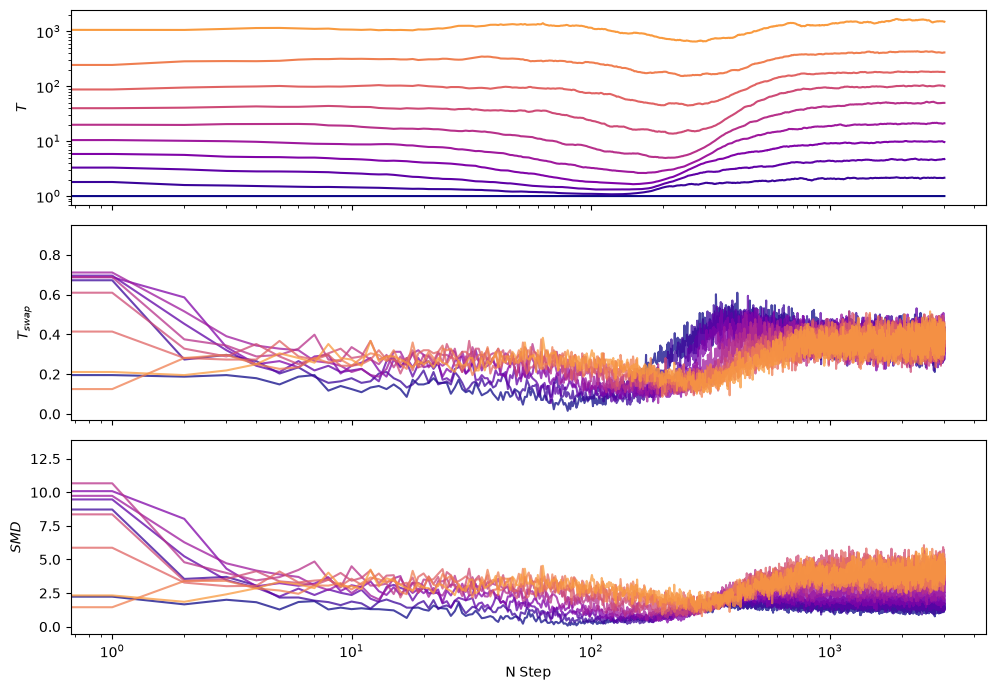

In [10]:
loc = sim.saveplace
Image(filename=f'{loc}/plots/betas/rates.png')

In [11]:
z_ti = sim.sampler.get_evidence_ti(discard=1000)
z_ss = sim.sampler.get_evidence_ss(discard=1000)
z_hy = sim.sampler.get_evidence_hybrid(discard=1000)

print(f'Thermodynamic Integration logZ = {z_ti[0]:.3f} ± {z_ti[1]:.3f}')
print(f'Stepping Stones logZ           = {z_ss[0]:.3f} ± {z_ss[1]:.3f}')
print(f'Hybrid Method logZ             = {z_hy[0]:.3f} ± {z_hy[1]:.3f}')

Thermodynamic Integration logZ = -894.743 ± 3.319
Stepping Stones logZ           = -894.532 ± 0.081
Hybrid Method logZ             = -894.652 ± 1.795


Which look fairly similar between them!

Now we can explore the results in the `/datalogs/51Peg/run_1/` folder:

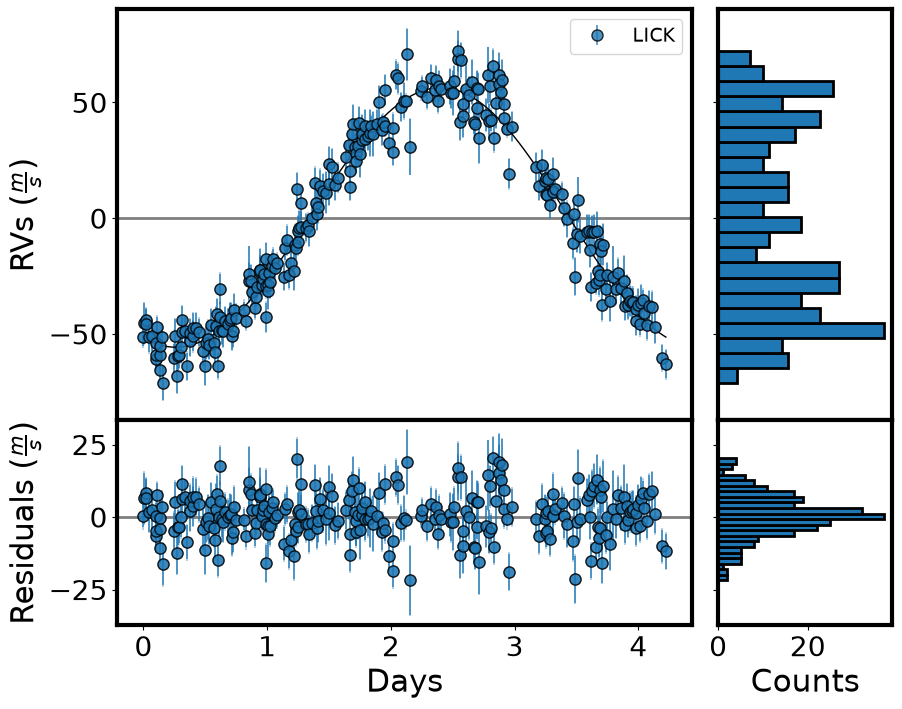

In [12]:
Image(filename=f'{loc}/plots/models/KeplerianBlock_1.png') 